# Who Moves the Bills? Text Analysis of Congressional Bill Actions

**DATASCI 530 - Assignment 4**\
**Author:** Xueqian Cheng

## Summary of findings

I used regular expressions to analyze the text of 3,303 actions on 1,494 bills in the 116th Congress.

- **Senate bills in the House:** 68.1% of the 116 House floor actions on Senate bills were motions to suspend the rules, and 15.5% were suspensions *as amended*. Most House members appear on only one bill. Rep. Mark Takano, chair of the Veterans' Affairs Committee, moved the most (9 bills).
- **Senate floor amendments:** 196 of 286 amendments name two senators ("proposed by X for Y"). This is not coauthorship: McConnell proposed amendments for 57 different colleagues, which reflects his role in managing floor business.
- **New insight:** women (Ms./Mrs.) used unanimous consent more than men (23.7% vs. 13.3% of requests), but two members drive most of this gap. Without them, the shares are similar (15.6% vs. 13.3%).


In [19]:
import re
import hashlib
import pandas as pd
import matplotlib.pyplot as plt

# Show long text columns in full
pd.set_option("display.max_colwidth", None)

bills_actions = pd.read_csv("../Lecture 09/data_raw/bills_actions.csv")

---
## Step 0 — Get to know the data

The dataset has 3303 rows and 7 columns. There are no missing values and 49 duplicate rows.

In [20]:
print(bills_actions.shape)
print(bills_actions.dtypes)
print("The dataset has " + str(bills_actions.isna().sum().sum()) + " missing values")
print("The dataset has " + str(bills_actions.duplicated().sum()) + " duplicate rows")

(3303, 7)
Congress       int64
bill_number    int64
bill_type        str
action           str
main_action      str
category         str
member_id      int64
dtype: object
The dataset has 0 missing values
The dataset has 49 duplicate rows


---
## Step 1 — Descriptive statistics

### 1a. How many distinct “bill” identifiers are there?
There are 1494 unique bills, identified jointly by bill_number and bill_type.

In [21]:
## Create identifible IDs
bills_actions["bill_id"] = bills_actions["bill_number"].astype(str) + bills_actions["bill_type"]
n_bills = bills_actions["bill_id"].nunique()
print(n_bills)

1494


### 1b. What share of rows belongs to each `category` and each `main_action`?

In [22]:
bills_actions["category"].value_counts(normalize=True).round(3)

category
amendment                       0.463
house bill                      0.273
senate bill                     0.156
house resolution                0.071
senate resolution               0.018
house joint resolution          0.007
house concurrent resolution     0.006
senate concurrent resolution    0.004
senate joint resolution         0.002
Name: proportion, dtype: float64

In [23]:
bills_actions["main_action"].value_counts(normalize=True).round(3)

main_action
house floor actions                              0.309
house amendment offered                          0.251
senate committee/subcommittee actions            0.131
other house amendment actions                    0.120
senate amendment proposed (on the floor)         0.087
house committee/subcommittee actions             0.066
reported to senate                               0.011
senate committee report filed after reporting    0.010
other senate amendment actions                   0.005
resolving differences -- house actions           0.004
senate floor actions                             0.004
house discharge petition filed                   0.001
resolving differences -- senate actions          0.001
Name: proportion, dtype: float64

---
## Step 2 — House floor actions on Senate bills

### 2a. Subset the data

Keep rows where `category` is Senate bill and `main_action` is House floor actions. There are 116 House floor actions that are associated with bills in the “Senate bills” category.


In [24]:
house_on_senate = bills_actions.query('category == "senate bill" \
                                      and main_action == "house floor actions"')
print(len(house_on_senate))

116


### 2b. Read the text

In [25]:
# Print 20 of the `action` texts in full
house_on_senate["action"].sample(20, random_state=1)

750    ORDER OF BUSINESS - Mr. Grijalva asked unanimous consent that debate under 1(c) of Rule XV on a motion to suspend the rules relating to S. 47 be extended to 50 minutes. Agreed to without objection.
655                                                                                                                                                  Mr. Rouda moved to suspend the rules and pass the bill.
681                                                                                                                                                Ms. Haaland moved to suspend the rules and pass the bill.
758                                                                                                                                                Ms. Haaland moved to suspend the rules and pass the bill.
704                                                                                                                                               Mr. Carbajal moved to suspend the 

### 2c. What share of actions were suspended? Suspended as amended?

In [26]:
# contains "moved to suspend"
house_on_senate["suspended"] = house_on_senate["action"].str.contains("moved to suspend the rules")
house_on_senate["suspended_as_amended"] = (
    house_on_senate["suspended"]
    # ended with "as amended"
    & house_on_senate["action"].str.contains(r"as amended\.?\s*$")
)

house_on_senate[["suspended", "suspended_as_amended"]].mean()

suspended               0.681034
suspended_as_amended    0.155172
dtype: float64

After reading a sample of the action texts, I defined an action as suspended if it contains the phrase "moved to suspend the rules". An action is suspended as amended if it is a suspension motion whose sentence ends with "as amended". Under these definitions, 68.1 percent of bill actions were motions to suspend the rules, and 15.5 percent of them were motions to suspend the rules and pass the bill as amended.

### 2d. Extract the names with a regex

In [27]:
pattern = r"((?:Mr|Ms|Mrs)\. .+?)(?= moved| asked)"
house_on_senate["member"] = house_on_senate["action"].str.extract(pattern)[0]

### 2e. Bills per person, and its distribution

1. Make a dataset with one row per member and the number of distinct bills they appear on.
2. Print the unique list of names.
3. Show the distribution

In [28]:
member_bills = (
    house_on_senate.groupby("member")["bill_id"].nunique()
    .reset_index(name="bills")
    .sort_values("bills", ascending=False)
)
print(member_bills["member"].unique())   # unique list of names
member_bills


<ArrowStringArray>
[           'Mr. Takano',           'Ms. Haaland',          'Mrs. Dingell',
              'Mr. Case',        'Ms. Kelly (IL)',           'Mr. Pallone',
              'Ms. Bass',           'Mr. DeFazio',         'Mr. Cicilline',
            'Ms. Norton',           'Mr. Huffman',            'Mrs. Luria',
          'Mr. Carbajal',           'Ms. Scanlon',           'Mrs. McBath',
             'Ms. Craig',   'Ms. Horn, Kendra S.',       'Ms. Jackson Lee',
           'Mr. Sherman',          'Mr. Peterson',            'Mr. Raskin',
            'Ms. Waters',              'Mr. Clay',          'Mr. Grijalva',
          'Mr. Cummings', 'Ms. Torres Small (NM)',             'Ms. Titus',
           'Ms. Stevens',          'Mr. Cisneros',           'Ms. Lofgren',
       'Ms. Kuster (NH)',           'Mr. Cleaver',             'Mr. Cohen',
          'Mr. Connolly',            'Mr. Correa',             'Ms. Eshoo',
           'Ms. DeGette',            'Mr. Nadler',            'Mr. Ne

,member,bills
30,Mr. Takano,9
41,Ms. Haaland,6
32,Mrs. Dingell,6
1,Mr. Case,5
44,Ms. Kelly (IL),5
23,Mr. Pallone,5
37,Ms. Bass,5
10,Mr. DeFazio,4
2,Mr. Cicilline,4
47,Ms. Norton,4


bills
1    29
2    10
3     3
4     4
5     4
6     2
9     1
Name: count, dtype: int64


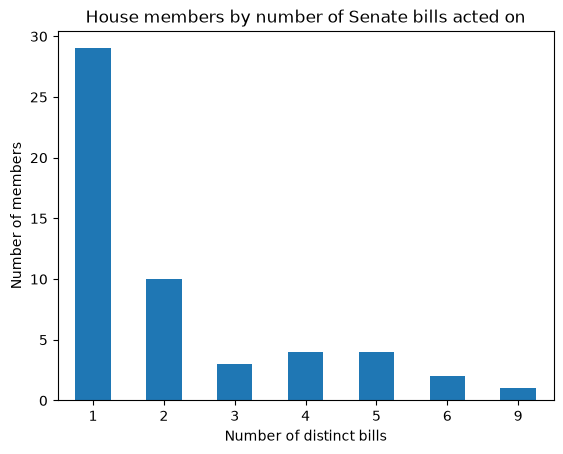

In [29]:
# distribution graph
dist = member_bills["bills"].value_counts().sort_index()
print(dist)

dist.plot(kind="bar")
plt.xlabel("Number of distinct bills")
plt.ylabel("Number of members")
plt.title("House members by number of Senate bills acted on")
plt.xticks(rotation=0)
plt.show()

In [30]:
# Who are at the top?
member_bills[member_bills["bills"] == member_bills["bills"].max()]
house_on_senate.loc[house_on_senate["member"] == "Mr. Takano", ["bill_id", "action"]]

,bill_id,action
567,3414s,Mr. Takano moved to suspend the rules and pass the bill.
581,863s,Mr. Takano asked unanimous consent to discharge from committee and consider.
641,3084s,"Mr. Takano moved to suspend the rules and pass the bill, as amended."
671,1646s,Mr. Takano asked unanimous consent to take from the Speaker's table and consider.
690,2216s,Mr. Takano moved to suspend the rules and pass the bill.
733,3637s,Mr. Takano asked unanimous consent to take from the Speaker's table and consider.
744,4072s,Mr. Takano asked unanimous consent to take from the Speaker's table and consider.
760,49s,Mr. Takano moved to suspend the rules and pass the bill.
775,785s,Mr. Takano moved to suspend the rules and pass the bill.


Most House members appear on only one bill. The member who moved the most bills is Rep. Mark Takano (9 distinct bills), who chaired the House Committee on Veterans' Affairs. 

---
## Step 3 — Senate floor amendments

### 3a. Subset and read

Keep rows with `main_action == "senate amendment proposed (on the floor)"`. 

In [31]:
senate_amendments = bills_actions[
    bills_actions["main_action"] == "senate amendment proposed (on the floor)"
].copy()

### 3b. Regex for senator names

In [32]:
examples = ["S.Amdt.2341 Amendment SA 2341 proposed by Senator Reed for Senator Wyden to Amendment SA 2301 .",
            "S.Amdt.2722 Amendment SA 2722 proposed by Senator Brown. (consideration: CR S7859)",
            "proposed by Senator McConnell for Senator Van Hollen. (consideration: ...)",
            "proposed by Senator Scott FL for Senator Blunt.",
            "proposed by Senator Braun for Senator Cortez Masto."]

# "Senator " + a capitalized word, plus an optional second capitalized word
# (Van Hollen, Cortez Masto, Scott FL). Lowercase words like "for"/"to" stop the match.
pattern = r"Senator ([A-Z][a-zA-Z]+(?: [A-Z][a-zA-Z]+)?)"
for text in examples:
    print(re.findall(pattern, text))

['Reed', 'Wyden']
['Brown']
['McConnell', 'Van Hollen']
['Scott FL', 'Blunt']
['Braun', 'Cortez Masto']


### 3c. Build the senators dataset

One row per amendment, with columns: `bill_id`, `n_senators`, `senator_1`, `senator_2`.

In [33]:
senators = senate_amendments["action"].str.findall(pattern)

amendment_senators = pd.DataFrame({
    "bill_id": senate_amendments["bill_id"],
    "n_senators": senators.str.len(),
    "senator_1": senators.str[0],   # who proposed it
    "senator_2": senators.str[1],   # on whose behalf ("for Senator Y"); NaN if none
})

# Quality check: rows where the regex found a different number of names than "Senator" appears
n_disagree = (amendment_senators["n_senators"] != senate_amendments["action"].str.count("Senator")).sum()
print(f"Rows where the counts disagree: {n_disagree}")
amendment_senators.head()

Rows where the counts disagree: 0


,bill_id,n_senators,senator_1,senator_2
0,1029s,2,McConnell,Cornyn
1,1031s,1,Hawley,NaN
2,1160s,2,McConnell,Smith
8,1253s,2,Feinstein,Cornyn
11,1309s,2,McConnell,Cardin


In [34]:
# distribution of n_senators (table)
amendment_senators["n_senators"].value_counts().sort_index()

n_senators
1     90
2    196
Name: count, dtype: int64

### 3d. How many different Senator 2s per Senator 1?

In [35]:
# Drop rows without a Senator 2 first, then groupby("senator_1")["senator_2"].nunique().
partners = (
    amendment_senators.dropna(subset=["senator_2"])   # keep only "X for Y" amendments
    .groupby("senator_1")["senator_2"].nunique()
    .sort_values(ascending=False)
)
partners

senator_1
McConnell    57
Reed         25
Cornyn        9
Cramer        7
Murkowski     6
Braun         5
Moran         4
Lee           3
Thune         3
Fischer       2
Sasse         2
Sullivan      2
Inhofe        1
Hawley        1
Grassley      1
Perdue        1
Feinstein     1
Rubio         1
Scott FL      1
Scott SC      1
Menendez      1
Name: senator_2, dtype: int64

This is not really coauthorship. In "proposed by Senator X for Senator Y", Senator Y is the author of the amendment, while Senator X only introduces it on the floor. The senators at the top of the list, such as McConnell with 57 partners, most likely reflect administrative roles in managing floor business rather than collaboration on the content.


---
## Step 4 — New insight
Compare `Mr.` vs `Ms./Mrs.` in House floor actions: do they use different procedures (suspension vs. unanimous consent)?

In [37]:
house_floor = bills_actions[bills_actions["main_action"] == "house floor actions"].copy()

# Who made the request, and which procedure: the member right before
# "moved to suspend the rules" or "asked unanimous consent"
proc_pattern = r"\b(Mr|Ms|Mrs)\. ([A-Z][^.]*?) (moved to suspend the rules|asked unanimous consent)"
house_floor[["title", "member", "procedure"]] = house_floor["action"].str.extract(proc_pattern)

procedures = house_floor.dropna(subset=["procedure"]).copy()
procedures["title"] = procedures["title"].map({"Mr": "Mr.", "Ms": "Ms./Mrs.", "Mrs": "Ms./Mrs."})
procedures["procedure"] = procedures["procedure"].map({"moved to suspend the rules": "Suspension",
                                                       "asked unanimous consent": "Unanimous consent"})
print(f"House floor actions: {len(house_floor)}, of which suspension or unanimous consent: {len(procedures)}")

# Table: number of actions and share of each procedure, by title
counts = pd.crosstab(procedures["title"], procedures["procedure"])
shares = pd.crosstab(procedures["title"], procedures["procedure"], normalize="index")
proc_table = counts.join(shares.add_suffix(" share").round(3))
proc_table["Members"] = procedures.groupby("title")["member"].nunique()
proc_table


House floor actions: 1020, of which suspension or unanimous consent: 856


procedure,Suspension,Unanimous consent,Suspension share,Unanimous consent share,Members
title,,,,,
Mr.,468,72,0.867,0.133,76
Ms./Mrs.,241,75,0.763,0.237,50


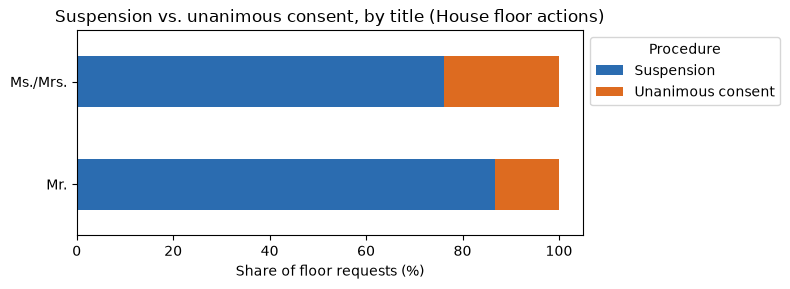

In [38]:
# Figure: share of each procedure, by title
ax = (shares * 100).plot(kind="barh", stacked=True, figsize=(8, 3), color=["#2b6cb0", "#dd6b20"])
ax.set_xlabel("Share of floor requests (%)")
ax.set_ylabel("")
ax.set_title("Suspension vs. unanimous consent, by title (House floor actions)")
ax.legend(title="Procedure", bbox_to_anchor=(1, 1))
plt.tight_layout()
plt.show()

In [ ]:
# Is the gap driven by a few members? Top unanimous consent requesters by title
top_uc = (procedures[procedures["procedure"] == "Unanimous consent"]
          .groupby("title")["member"].value_counts().groupby("title").head(3))
print(top_uc)

# Same shares without the two biggest requesters
others = procedures[~procedures["member"].isin(["Kelly (IL)", "Lofgren"])]
pd.crosstab(others["title"], others["procedure"], normalize="index").round(3)


**Do men and women use different floor procedures?** I took the member right before "moved to suspend the rules" or "asked unanimous consent" in the 1,020 House floor actions, which gives 856 requests by 126 members, and compared their titles. Ms./Mrs. members used unanimous consent for 23.7% of their requests, compared with 13.3% for Mr. members, so at first women seem to rely on it more. But this gap comes mostly from two members: Ms. Kelly (IL) and Ms. Lofgren made 32 of the 75 unanimous consent requests by women, all of them to discharge a bill from committee or take it from the Speaker's table. Without them, the share for women falls to 15.6%, close to the 13.3% for men. Suspension is the main procedure for everyone. The difference reflects a few members' floor roles rather than gender.
